In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
nW = 1024 * 2 * 2
nG = 1024 * 2

In [4]:
# constants
c = 0.03    # cm/ps

# Laser pulse duration
tau = 0.150 / 2 / np.sqrt(np.log(2))   # ps

# Laser beam waist size
a0 = 30e-4 / 2 / np.sqrt(np.log(2))     # поперечный размер cm

# Refractive indices
n_gr = 2.23
n_opt = 2.16
# Other
# A = 1
I = 10      # GW/cm^2
d33 = 166   # pm/V
# p_y = d33*8*np.pi*1e-7/(n_opt*c)    # B/M
p_y = 768.5


FUNCTIONS

In [5]:
# epsilon
def eps(w_):
    e_0 = 26
    e_inf = 10
    w_TO = 2 * np.pi * 7.44  # THz
    gamma = 2 * np.pi * 0.844 # THz
    
    epsilon = e_inf + (e_0 - e_inf) * w_TO**2 / (w_TO**2 - w_**2 + 1j * gamma * w_)
    return epsilon

In [6]:
def k(w_, g_):
    k = np.zeros((np.size(w_), np.size(g_)), dtype=complex)
    
    eps_ = eps(w_)
    
    for i in range(np.size(w_)):
        for j in range(np.size(g_)):
            # k[i][j] = (w_[i] / c)**2 * eps_[i] - g_[j]**2
            if not i == 0:
                k[i][j] = (w_[i] / c) * np.sqrt(eps_[i] - (g_[j] * c / w_[i])**2)
            else:
                k[i][j] = -1j * g_[j]

            if np.imag(k[i][j]) > 0:
                k[i][j] = np.conjugate(k[i][j])
    
    return k 

In [7]:
def F(w_, tau_):
    return tau_ / (2 * np.sqrt(np.pi)) * np.exp(-(w_ * tau_ / 2)**2)

def G(g_, a0_):
    # return a0_ / (2 * np.sqrt(np.pi)) * np.exp(-(g_ * a0_ / 2)**2)
    return a0_**3 * np.sqrt(np.pi)/ 2 * np.exp(-(g_ * a0_ / 2)**2)*(1 - (g_*a0_)**2/2)

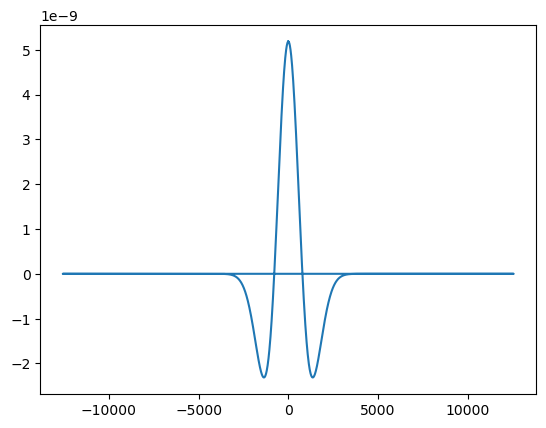

In [17]:
GGG = G(g, a0)
plt.plot(g, GGG)


In [18]:
def ey_field(w_, g_, k_):
    ey = np.zeros((np.size(w_), np.size(g_)), dtype=complex)
    FF = F(w_, tau)
    GG = G(g_, a0)
    
    
    for i in range(1, np.size(w_)):
        for j in range(1, np.size(g_)):
            arg_up = FF[i] * GG[j]
            arg_down = (k_[i][j] * c / w_[i])**2 - n_gr**2
            ey[i][j] = arg_up / arg_down
    for i in range(1):
        for j in range(1):       
            if  i == 0:
                arg_up = 0
                arg_down = 1
            # if np.abs(w[i]) < 1e-4 or np.abs(g[j]) < 1e-4:
            #     arg_down = w[i]**2*eps(0)/c**2 - n_gr**2
                ey[i][j] = arg_up / arg_down
    return ey*4*np.pi
    

CALCULATIONS

In [16]:
w_max = 2*np.pi * 10.0
w, dw = np.linspace(-w_max, w_max-dw, num=nW, retstep=True)
w = np.fft.fftshift(w)
w *= -1
print(w_max)
print(np.min(np.abs(w)))
print(dw)
# plt.plot(w)

62.83185307179586
0.0
0.030679615757712823


In [15]:
dt = 0.05
w = np.fft.fftfreq(nW, dt/(2 * np.pi))
dw = np.abs(w[1] - w[0])
print(np.max(w))
print(np.min(w))
print(dw)
print(w[0])
# plt.plot(ww)

62.80117345603815
-62.83185307179586
0.030679615757712823
0.0


In [13]:
g_max = 2*np.pi * 2000.0
g, dg = np.linspace(-g_max, g_max-dg, num=nG, retstep=True)
g = np.fft.fftshift(g)
print(g_max)
print(dg)

12566.370614359172
12.271846303085129


In [12]:
dx = 0.00025
g = np.fft.fftfreq(nG, dx/(2 * np.pi))
dg = np.abs(g[1] - g[0])
print(np.max(g))
print(np.min(g))
print(dg)
# plt.plot(ww)

12554.098768056087
-12566.370614359172
12.271846303085129


In [11]:
# plt.plot(w/2/np.pi, F(w, tau))

In [12]:
# plt.plot(g/2/np.pi, F(g, a0))

In [19]:
print(f'x_max = {np.pi / dg} cm')
print(f'xi_max = {np.pi / dw} ps')

x_max = 0.256 cm
xi_max = 102.4 ps


In [20]:
print(f'dx = {np.pi / g_max} cm')
print(f'dt = {np.pi / w_max} ps')

dx = 0.00025 cm
dt = 0.05 ps


In [21]:
t0_idx = int((0.1 / (c / n_gr)) // (np.pi / w_max))
print(t0_idx)

148


In [22]:
kk = k(w, g)

In [25]:
eyy = ey_field(w, g, kk)
print(np.max(np.abs(eyy)))

3.529904445920896e-08


In [49]:
z = np.linspace(0, 0.2, num=200)
ez = np.zeros((np.size(z), np.size(g)), dtype=complex)
et = np.zeros(np.size(w), dtype = complex)

for i in range(np.size(z)):
    eyy_tmp = np.zeros((np.size(w), np.size(g)), dtype=complex)
    for j in range(np.size(w)):
        eyy_tmp[j][:] = eyy[j][:] * np.exp(-1j * w[j] * z[i] / (c / n_gr))
    ee = np.fft.fft2(eyy_tmp) * (dw*dg)
    ez[i][:] = ee[t0_idx][:]
    
    
        
        

In [1]:
for i in range(np.size(w)):
    eyy_tmp[i][:] = eyy[i][:] * np.exp(-1j * w[i] * z[80] / (c / n_gr))
ee = np.fft.fft2(eyy_tmp) * (dw*dg)
et[i] = ee[i][10]

NameError: name 'np' is not defined

In [73]:
ez*=p_y
ez_max = np.max(np.real(ez))
print(ez_max)
et*=p_y


480440170702471.56


In [69]:
max_num =0
str = 0
row = 0
for i in range(ez.shape[0]):
    for j in range(ez.shape[1]):
        if np.real(ez[i][j]) > max_num:
            max_num = np.real(ez[i][j])
            str = i
            row = j
print(str,',',row)

99 , 8


In [120]:
np.shape(wedge)

(2048, 200)

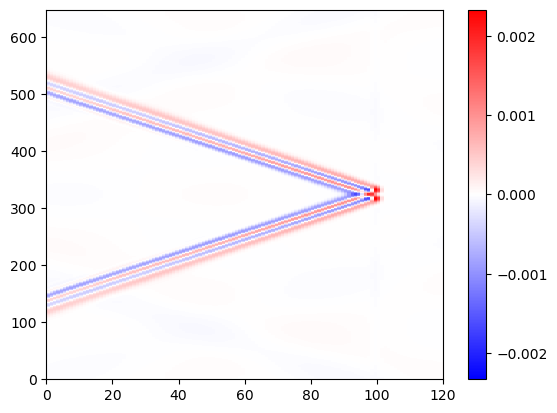

In [122]:
wedge = np.transpose(ez.real)
# wedge = np.transpose(ez.imag)
wedge = np.fft.fftshift(wedge, axes=0)
plt.pcolormesh(wedge[700:-700,:120],
               cmap='bwr',
               vmin=-np.max(np.abs(wedge)),
               vmax=np.max(np.abs(wedge))
               )
plt.colorbar()

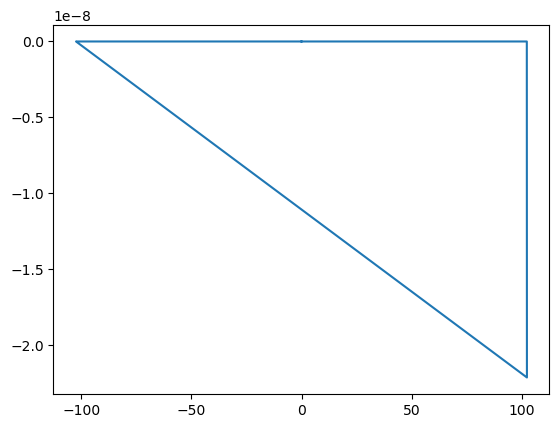

In [76]:
osc = np.transpose(et.real)
# wedge = np.transpose(ez.imag)
osc = np.fft.fftshift(osc, axes=0)
# t = np.arange(0, nW, dt)
t = np.fft.fftfreq(nW, dw/(2 * np.pi))
plt.plot(t, osc)


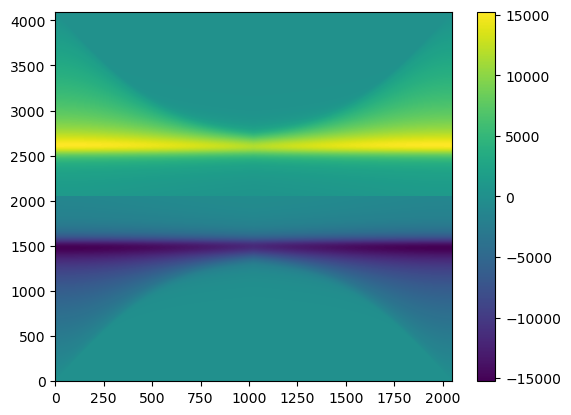

In [115]:
plt.pcolormesh(kk.real)
plt.colorbar()

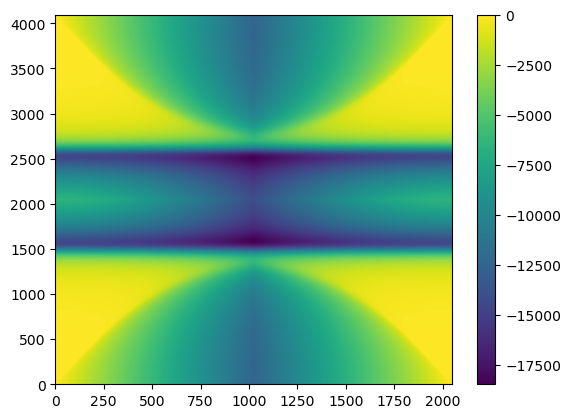

In [116]:
plt.pcolormesh(kk.imag)
plt.colorbar()

In [117]:
ey_real = np.real(eyy)
max_real = np.max(ey_real)

plt.pcolormesh(ey_real,
               cmap='bwr',
               vmin=-max_real/1000,
               vmax=max_real/1000
               )
plt.colorbar()

MemoryError: Unable to allocate 256. MiB for an array with shape (4096, 2048, 4) and data type float64

<Figure size 640x480 with 2 Axes>

MemoryError: Unable to allocate 64.0 MiB for an array with shape (4097, 2049, 2) and data type int32

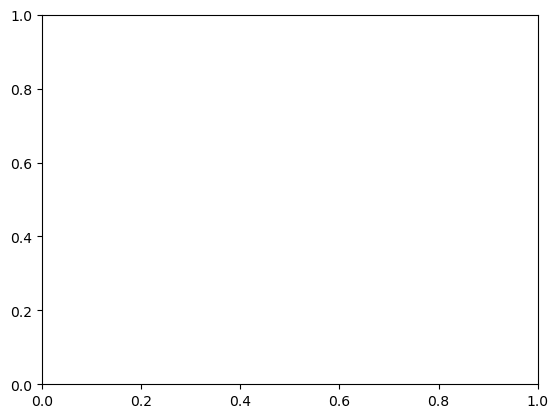

In [118]:
ey_imag = np.imag(eyy)
max_imag = np.max(ey_imag)

plt.pcolormesh(ey_imag,
               cmap='bwr',
               vmin=-max_imag, vmax=max_imag
               )
plt.colorbar()

Fast Fourier Transform

In [ ]:
eee = np.fft.fft2(eyy)

In [ ]:
ee_real = np.real(eee)
max_ee_real = np.max(ee_real)

plt.pcolormesh(ee_real,
               cmap='bwr',
               vmin=-max_ee_real, vmax=max_ee_real
               )
plt.colorbar()

In [ ]:
ee_imag = np.imag(eee)
max_ee_imag = np.max(ee_imag)

plt.pcolormesh(ee_imag,
               cmap='bwr',
               vmin=-max_ee_imag, vmax=max_ee_imag
               )
plt.colorbar()